# 06 · PCA, K-means y aceptación/rechazo de huellas
**Trabajo Final IA I · Ingeniería en Mecatrónica · UNCUYO**

Esta bitácora conserva el recorrido completo: referencia con todas las características,
selección de columnas para mejorar el agrupamiento y calibración del rechazo.
No se sustituyen resultados anteriores por una historia de éxito sin antecedentes.

Los resultados provienen de tres ejecuciones reales del autor en Windows/Python 3.14.0:

| Avance | Identificador UTC |
|---|---|
| PCA y K-means de referencia | 20261022T160116_346229Z |
| Selección de características | 20261023T014705_319737Z |
| Calibración del rechazo | 20261023T021746_872267Z |

El notebook actualizado es de **solo lectura**: consulta las evidencias publicadas,
muestra figuras y comprueba cantidades y fórmulas; no vuelve a entrenar ni recalibrar.
Puede ejecutarse desde un clon sin las matrices de características locales.
La evaluación final sobre prueba continúa pendiente.

Fuentes: consigna Trabajo Final 2026 y clase de aprendizaje consultadas durante el desarrollo;
código versionado y ejecuciones compartidas por el autor. El reenvío posterior del ZIP de
material no estuvo disponible; no se lo atribuye como una nueva lectura.


In [1]:
from pathlib import Path
import csv, hashlib, json
import numpy as np
from IPython.display import display, Image, Markdown

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/conjunto_v1.json").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abrí el notebook dentro del repositorio.")
EVIDENCIA = RAIZ / "documentos/evidencias/06_huellas_referencia"

def leer_json(nombre):
    return json.loads((EVIDENCIA / nombre).read_text(encoding="utf-8-sig"))

def leer_csv(nombre):
    with (EVIDENCIA / nombre).open(encoding="utf-8-sig", newline="") as f:
        return list(csv.DictReader(f))

def tabla(filas, campos=None):
    if not filas:
        print("Sin registros")
        return
    campos = campos or list(filas[0])
    texto = "| " + " | ".join(campos) + " |\n| " + " | ".join(["---"] * len(campos)) + " |\n"
    texto += "\n".join("| " + " | ".join(str(r[c]) for c in campos) + " |" for r in filas)
    display(Markdown(texto))

def figura(nombre, ancho=1100):
    display(Image(filename=str(EVIDENCIA / nombre), width=ancho))

procedencia = leer_json("procedencia.json")
for archivo in procedencia["archivos"]:
    digest = hashlib.sha256((EVIDENCIA / archivo["ruta"]).read_bytes()).hexdigest()
    if digest != archivo["sha256"]:
        raise ValueError("Evidencia modificada: " + archivo["ruta"])
referencia = leer_json("01_referencia/resumen.json")
seleccion = leer_json("02_seleccion/resumen.json")
rechazo = leer_json("03_rechazo/resumen.json")
print("Evidencias verificadas:", len(procedencia["archivos"]))
print("Entorno de las mediciones:", rechazo["python"], rechazo["plataforma"])
print("Modelos reajustados al ejecutar este notebook: NO")


Evidencias verificadas: 39
Entorno de las mediciones: 3.14.0 Windows-11-10.0.26200-SP0
Modelos reajustados al ejecutar este notebook: NO


## De imágenes a distancias

Cada imagen se representa por un vector de 144 características GLCM. Las filas son
capturas; las columnas mantienen el mismo significado entre capturas. En audio se
obtienen 160 componentes, y la clase es la palabra, no el hablante.

Antes de comparar vectores se estandariza cada columna con entrenamiento:

$$\boxed{z_j=\frac{x_j-\mu_j^{train}}{\sigma_j^{train}}}.$$

El escalador usa `ddof=0`. Las tablas estadísticas de la etapa 05 usan `ddof=1` para DE
muestral. Las columnas constantes se conservan en la referencia con escala 1.
Identidad, hablante y partición no se agregan como componentes numéricos.

PCA construye combinaciones lineales de las columnas estandarizadas. Busca direcciones
de mayor variación sin utilizar etiquetas para separarlas. Cada punto es una muestra.
Una mezcla de colores en dos dimensiones no prueba inseparabilidad en todo el espacio.


## Referencia: todas las características

Se ajustaron escalador y PCA solo con entrenamiento; en huellas se usaron únicamente
las identidades autorizadas. Los intrusos no formaron un cuarto grupo.
K-means se ajustó en las 144 columnas estandarizadas, y PCA se usó para visualizar.
La separación obtenida fue parcial: A02 se distinguió mejor que A01 y A03.


| Modalidad | Columnas | Varianza PC1-PC2 (%) | Componentes para 95 % |
| --- | --- | --- | --- |
| huellas | 144 | 80.84 | 3 |
| audio | 160 | 27.75 | 52 |

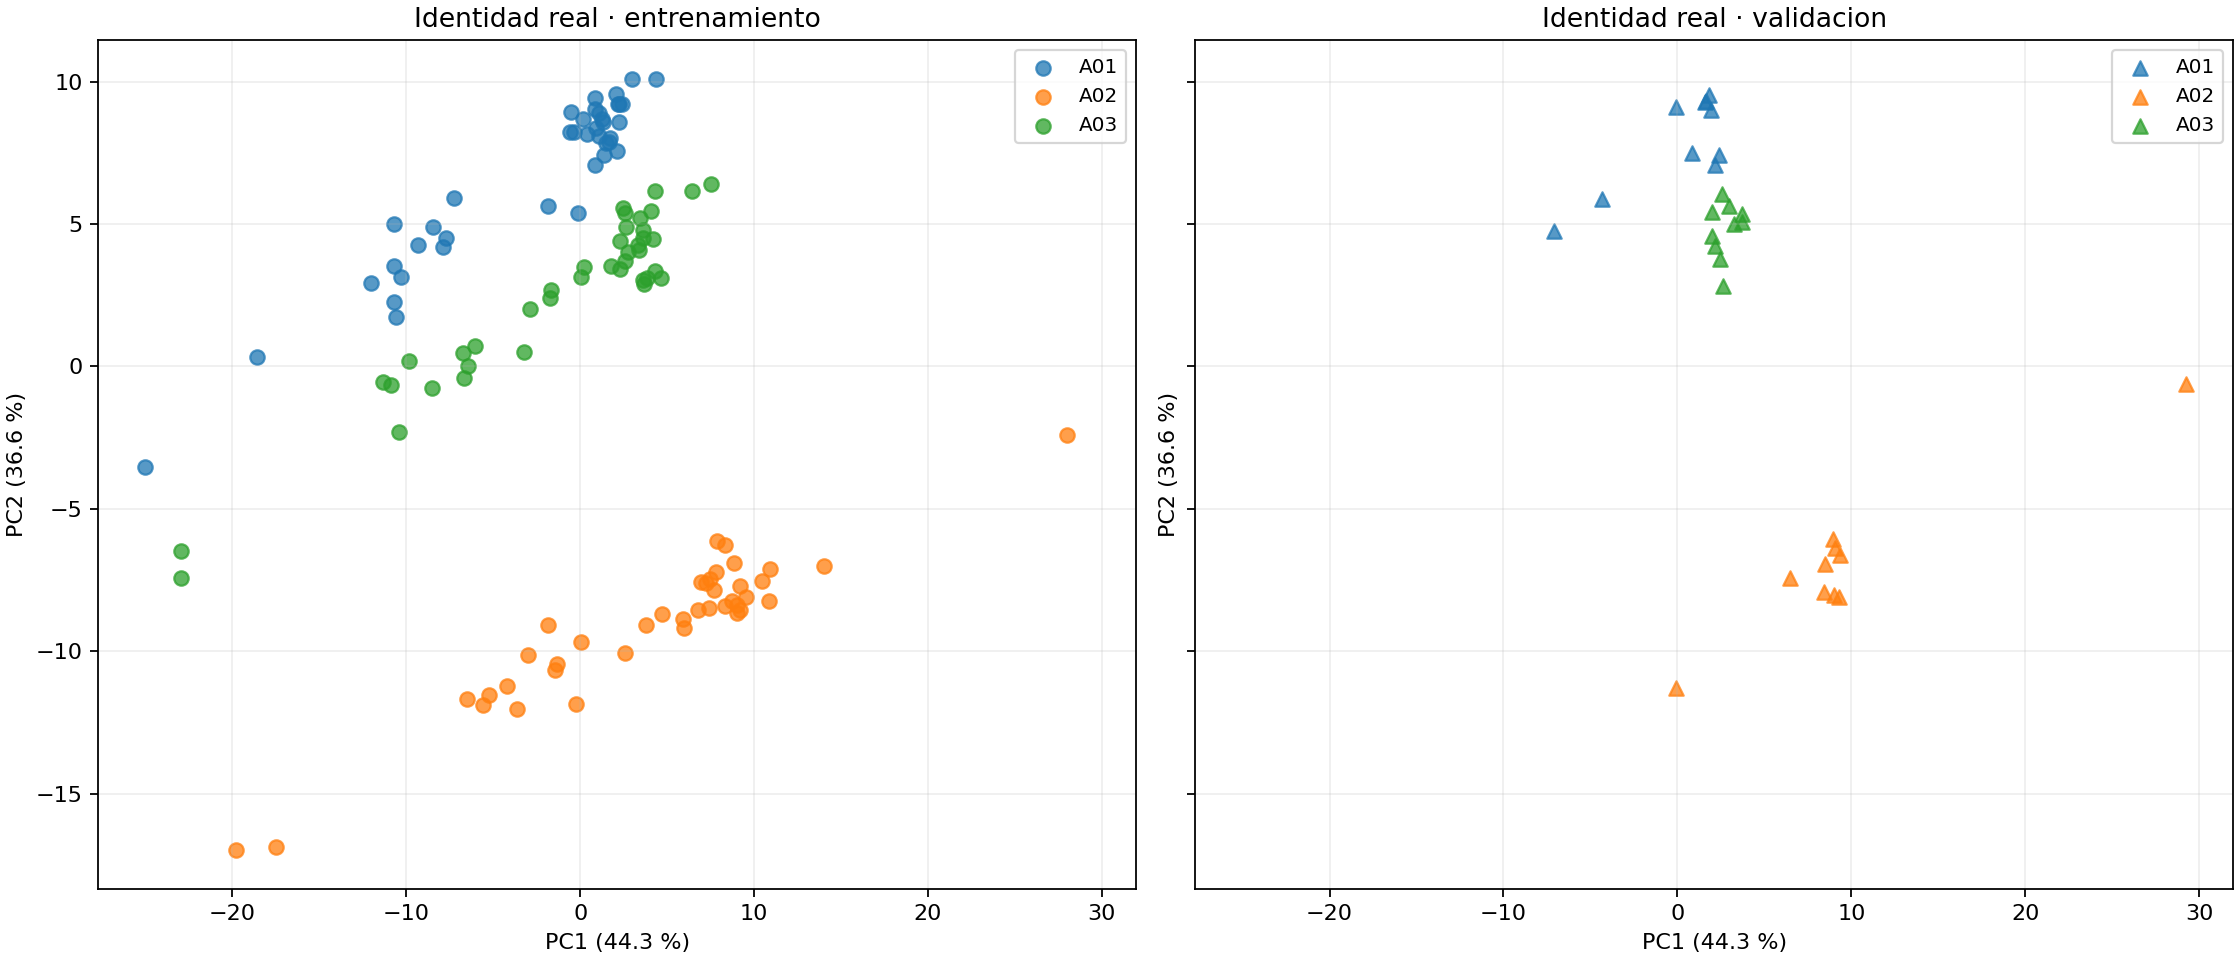

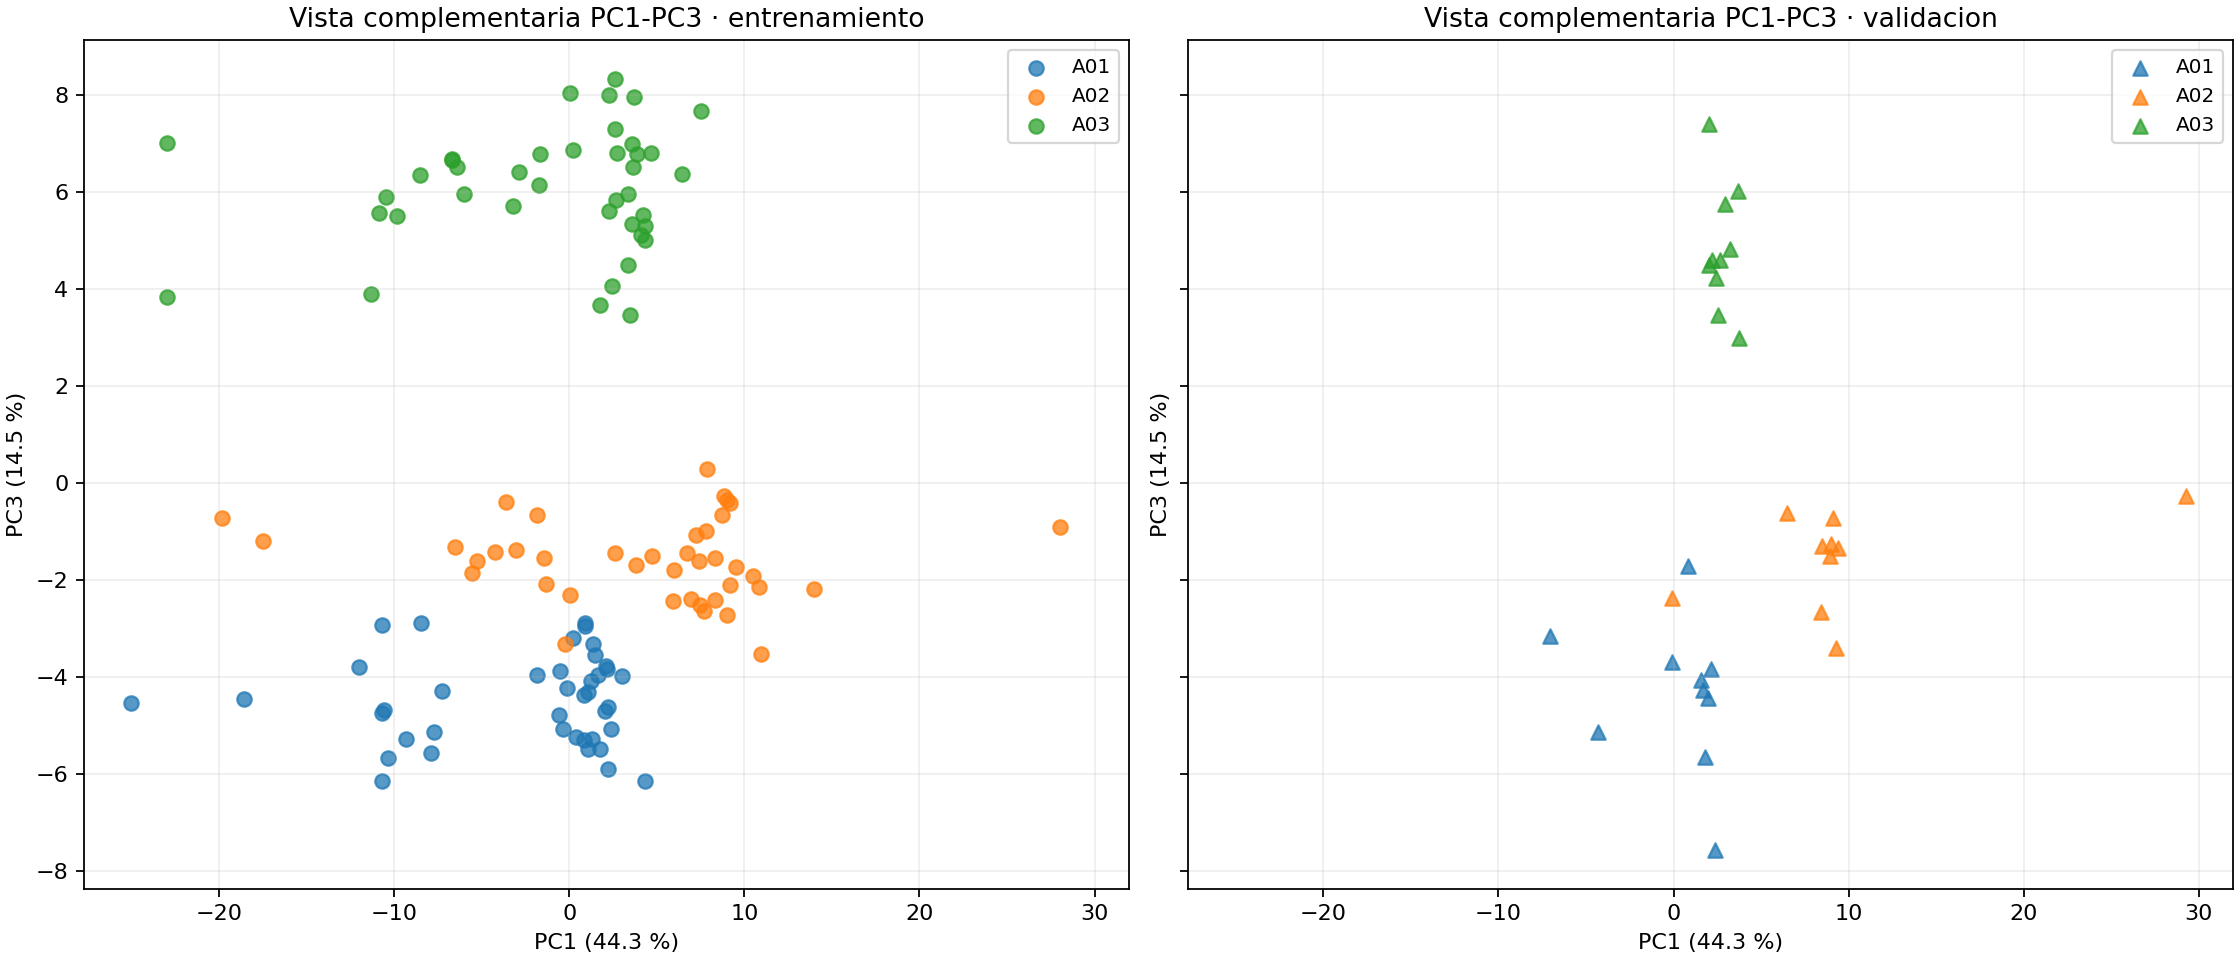

In [2]:
tabla([
    {"Modalidad": m, "Columnas": referencia[m]["caracteristicas_entrada"],
     "Varianza PC1-PC2 (%)": round(referencia[m]["pc1_pc2_porcentaje"], 2),
     "Componentes para 95 %": referencia[m]["componentes_95"]}
    for m in ["huellas", "audio"]])
figura("01_referencia/huellas/pca_clases.png")
figura("01_referencia/huellas/pca_pc3.png")


En huellas, PC1-PC2 conserva 80.84 % de la variación y PC3 aporta otro 14.48 %.
La vista PC1-PC3 permite apreciar mejor diferencias entre A01 y A03, pero eso no garantiza
que K-means encuentre grupos de identidad: su objetivo es reducir inercia.
El 95.32 % corresponde a conservar las TRES componentes, no solo el plano PC1-PC3.

En audio, H001-H006 permanecen en entrenamiento según el mapa persistente. No hay todavía
validación independiente con voces nuevas. Se realizó PCA exploratorio por palabra y hablante;
no se implementó K-means de audio ni K-NN en esta etapa.


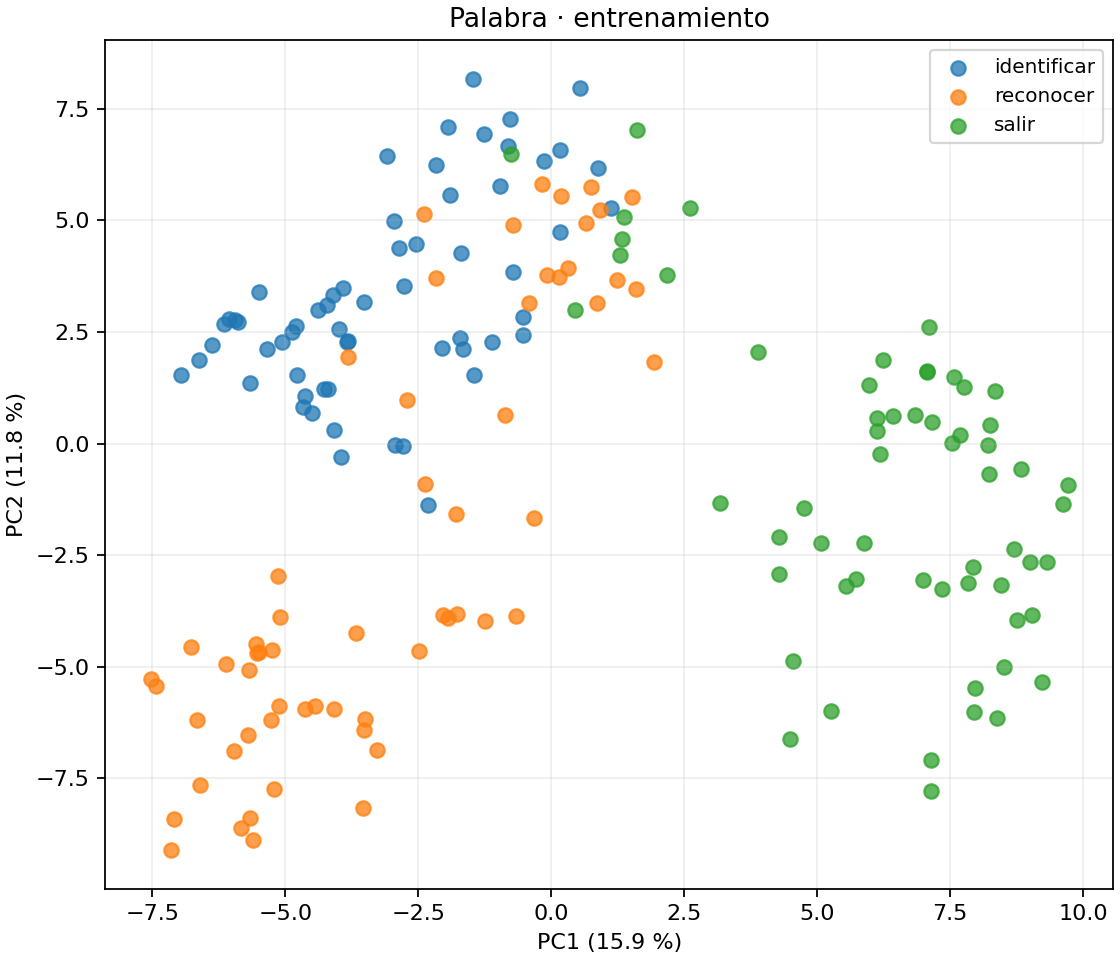

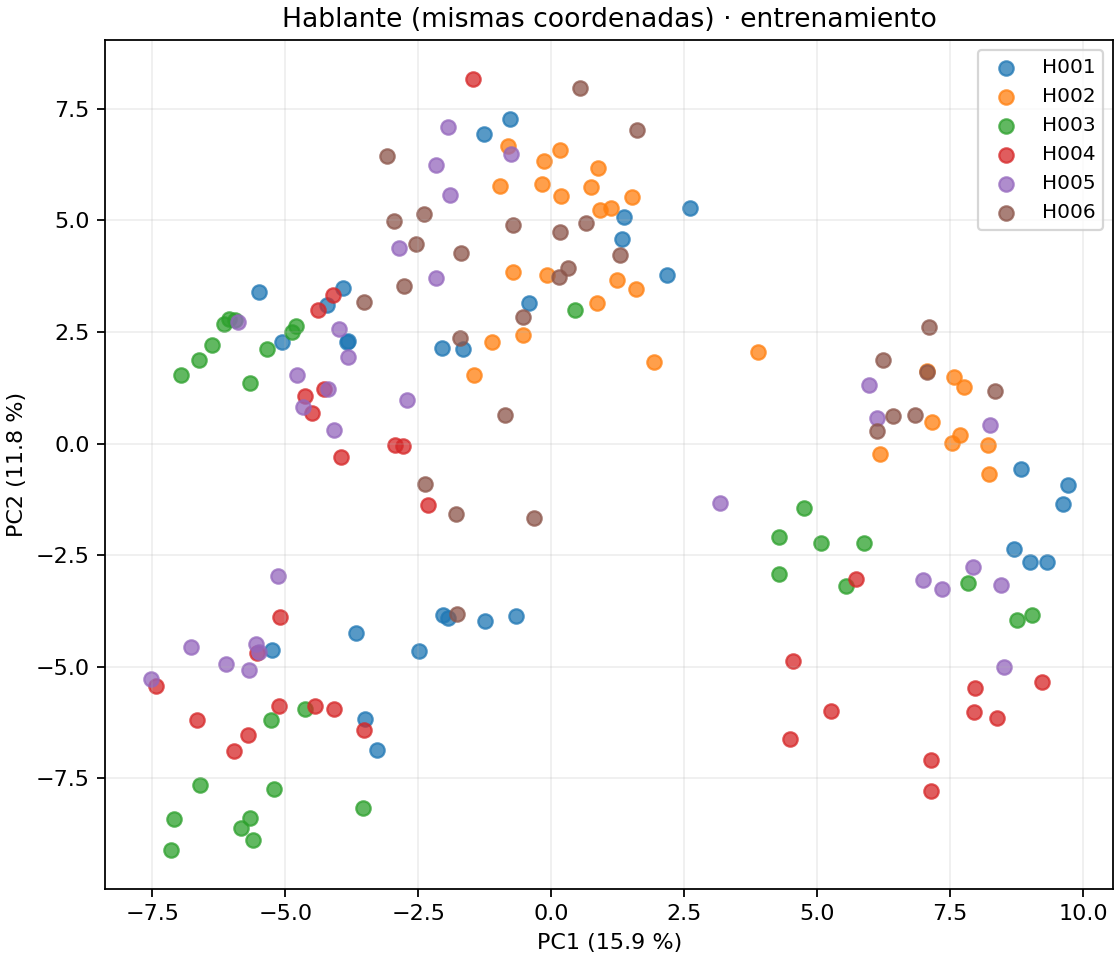

PC1-PC2 de audio conserva 27.75 %.


In [3]:
figura("01_referencia/audio/pca_clases.png", ancho=850)
figura("01_referencia/audio/pca_hablantes.png", ancho=850)
print("PC1-PC2 de audio conserva", round(referencia["audio"]["pc1_pc2_porcentaje"], 2), "%.")


## Mejora: seleccionar columnas sin eliminar capturas

Se mantuvieron las mismas identidades, semillas, muestras y particiones. El extractor
sigue produciendo 144 valores. Se seleccionaron 72 para el modelo usando:

$$\boxed{S_j=\frac{\sum_c n_c(\bar x_{cj}-\bar x_j)^2}
{\sum_c\sum_{i\in c}(x_{ij}-\bar x_{cj})^2}}.$$

Se favorecen diferencias entre identidades grandes respecto de la dispersión dentro de
cada identidad. Una DE alta por sí sola no implica mala característica; las unidades
distintas tampoco se comparan mediante DE brutas. Este indicador es invariante a escala lineal.

La selección es **supervisada** porque utiliza identidades de entrenamiento. K-means
no recibe etiquetas al formar los grupos. No se debe describir todo el procedimiento
como puramente no supervisado.

Se compararon todas las columnas, la mejor mitad y el mejor cuarto con cinco pliegues
internos de entrenamiento. En CADA pliegue se recalculan ranking y escalado solo con
su subentrenamiento. El criterio es mayor ARI medio; empate: conservar más columnas.
La mitad y el cuarto empataron y se eligieron 72, sin usar validación para elegir entre ellos.
Las divisiones internas siguen compartiendo las tres bases conocidas: no prueban
generalización a nuevos dedos ni a huellas reales.


| columnas | ari_medio | ari_minimo | coincidencia_media |
| --- | --- | --- | --- |
| 144 | 0.41605646805492497 | 0.37295528898582336 | 0.6 |
| 72 | 1.0 | 1.0 | 1.0 |
| 36 | 1.0 | 1.0 | 1.0 |

Columnas elegidas: 72
Familias seleccionadas: {'contraste': 21, 'correlacion': 32, 'homogeneidad': 19}


| Modelo | Partición | n | ARI | Identificación sin rechazo (%) |
| --- | --- | --- | --- | --- |
| referencia | entrenamiento | 120 | 0.4477 | 65.83 |
| referencia | validacion | 30 | 0.5436 | 70.0 |
| seleccionada | entrenamiento | 120 | 1.0 | 100.0 |
| seleccionada | validacion | 30 | 1.0 | 100.0 |

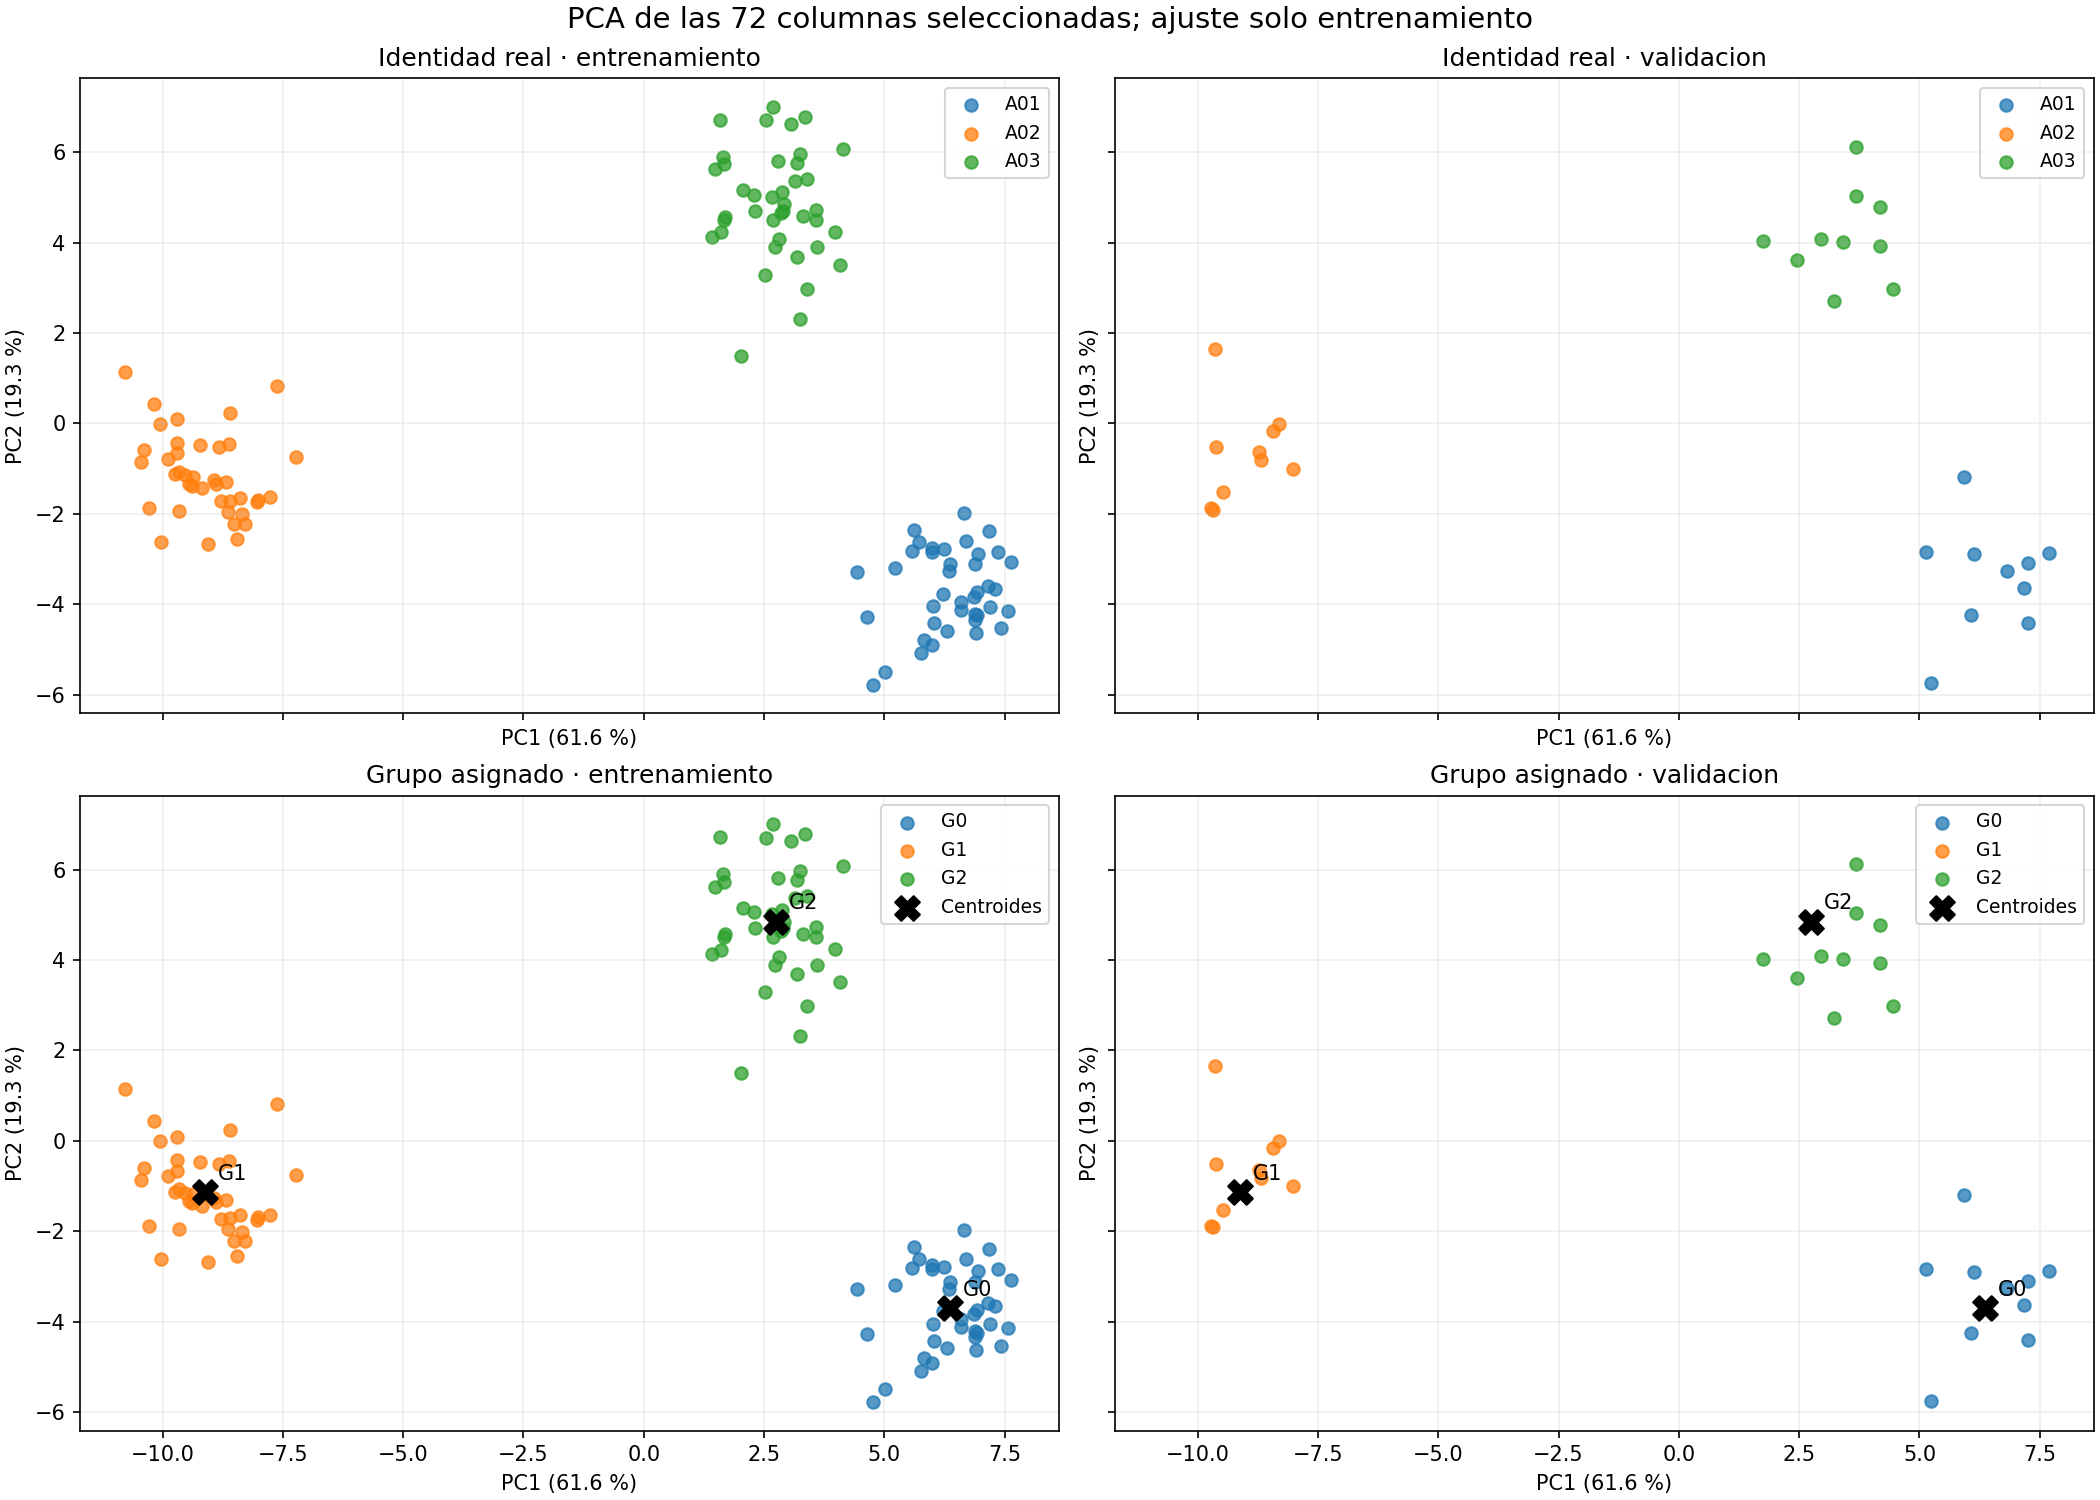

In [4]:
tabla(leer_csv("02_seleccion/comparacion_cv_train.csv"))
print("Columnas elegidas:", seleccion["columnas_elegidas"])
print("Familias seleccionadas:", seleccion["familias_seleccionadas"])
tabla([
    {"Modelo": nombre, "Partición": parte, "n": m["n"],
     "ARI": round(m["ari"], 4), "Identificación sin rechazo (%)": round(100*m["coincidencia"], 2)}
    for nombre, resultados in seleccion["modelos"].items() for parte, m in resultados.items()])
figura("02_seleccion/pca_seleccionada.png")


## Qué hace K-means y qué cambió

Se conserva k=3. K-means alterna asignar cada muestra al centroide más cercano y recalcular
los centroides como medias de las muestras asignadas, buscando reducir:

$$\boxed{J=\sum_i\|\mathbf z_i-\boldsymbol\mu_{g(i)}\|_2^2}.$$

Se usa k-means++, 20 inicializaciones, semilla 20261022, algoritmo Lloyd, máximo 300
iteraciones y tolerancia 0.0001. El inicio favorece centros separados, sin elegir uno por
identidad conocida. Se conserva la ejecución de menor inercia; no se crean 20 grupos.
Las tres semillas de estabilidad comprobadas mantuvieron los resultados de esta variante.

El cambio fue la entrada al mismo algoritmo: pasó de 144 a 72 columnas. Los tres grupos
no se redujeron. PCA se recalculó para dibujar el espacio seleccionado, pero K-means
continúa trabajando en todas sus 72 dimensiones, no únicamente sobre PC1-PC2.
La correspondencia grupo-identidad se aprende después del ajuste solo con entrenamiento
y se conserva en validación. Los nombres G0/G1/G2 son arbitrarios.

La identificación sin rechazo fue 120/120 en entrenamiento y 30/30 en validación.
Eso no significa todavía que los intrusos se rechacen: cualquier vector tiene un centroide cercano.


## Umbral de aceptación: distancia euclidiana en 72 dimensiones

Con los centroides y el escalador congelados se calcula:

$$\boxed{d_k=\sqrt{\sum_{j=1}^{72}(z_j-\mu_{kj})^2},\qquad d_{min}=\min_k d_k}.$$

Se acepta si $d_{min}\le\tau$ y se muestra la identidad asociada al grupo. Si se rechaza,
la identidad visible queda vacía. Las distancias no son porcentajes de parecido ni se
miden en el plano PCA. No se reajustan centros con cada muestra de validación.

Las 120 autorizadas de entrenamiento ya adaptaron las columnas, escalas y centros.
Para calibrar aceptación se utilizan las 30 autorizadas y 20 intrusas de VALIDACIÓN.
El umbral se considera un parámetro ajustado con validación; los resultados de esa misma
calibración no constituyen una evaluación final independiente.


In [5]:
decisiones = leer_csv("03_rechazo/decisiones_validacion.csv")
curva = leer_csv("03_rechazo/tasas_por_umbral.csv")
distancias = np.array([float(r["distancia"]) for r in decisiones])
unicas = np.unique(distancias)
candidatos = np.unique(np.r_[0., unicas[:-1] + np.diff(unicas)/2, unicas[-1]])
assert np.allclose(candidatos, [float(r["umbral"]) for r in curva])
print("Muestras de validación:", len(decisiones))
print("Distancias mínimas distintas:", len(unicas))
print("Candidatos:", len(candidatos), "= 1 cero +", len(unicas)-1, "puntos medios + 1 máximo")
print("Umbral guardado:", rechazo["resultado_calibracion"]["umbral"])


Muestras de validación: 50
Distancias mínimas distintas: 50
Candidatos: 51 = 1 cero + 49 puntos medios + 1 máximo
Umbral guardado: 5.292172575840761


### Por qué aparecen 51 candidatos

Las 50 muestras produjeron 50 distancias distintas. Se ordenan $t_1<\cdots<t_{50}$ y
se prueban cero, los 49 puntos medios entre valores consecutivos y el máximo $t_{50}$:

$$\boxed{1+49+1=51\text{ umbrales candidatos}}.$$

No son características ni muestras nuevas. Si cambian las distancias o hay empates,
puede cambiar la cantidad de candidatos. Entre dos distancias consecutivas no cambia
la decisión de las muestras observadas.

Para cada candidato se calcula:

$$\boxed{FAR=\frac{\text{intrusos aceptados}}{\text{intrusos}},\quad
FRR=\frac{\text{autorizados rechazados}}{\text{autorizados}},\quad BER=\frac{FAR+FRR}{2}}.$$

Se minimiza BER. Desempate: menor FAR y luego menor umbral. Se da el mismo peso a las
tasas de ambos grupos; no es una política de seguridad universal ni un requisito FAR=FRR.


| grupo | aceptadas | rechazadas |
| --- | --- | --- |
| autorizado | 29 | 1 |
| intruso | 0 | 20 |

| identidad | grupo | n | aceptadas | rechazadas | errores_identidad_aceptada |
| --- | --- | --- | --- | --- | --- |
| A01 | autorizado | 10 | 10 | 0 | 0 |
| A02 | autorizado | 10 | 9 | 1 | 0 |
| A03 | autorizado | 10 | 10 | 0 | 0 |
| I01 | intruso | 10 | 0 | 10 | 0 |
| I02 | intruso | 10 | 0 | 10 | 0 |

FAR: 0.0 %
FRR: 3.33 %
BER: 1.67 %
Errores conservados:


| muestra | identidad_real | distancia | estado | error |
| --- | --- | --- | --- | --- |
| A02_M22 | A02 | 10.769863514562502 | NO AUTORIZADO | falso_rechazo |

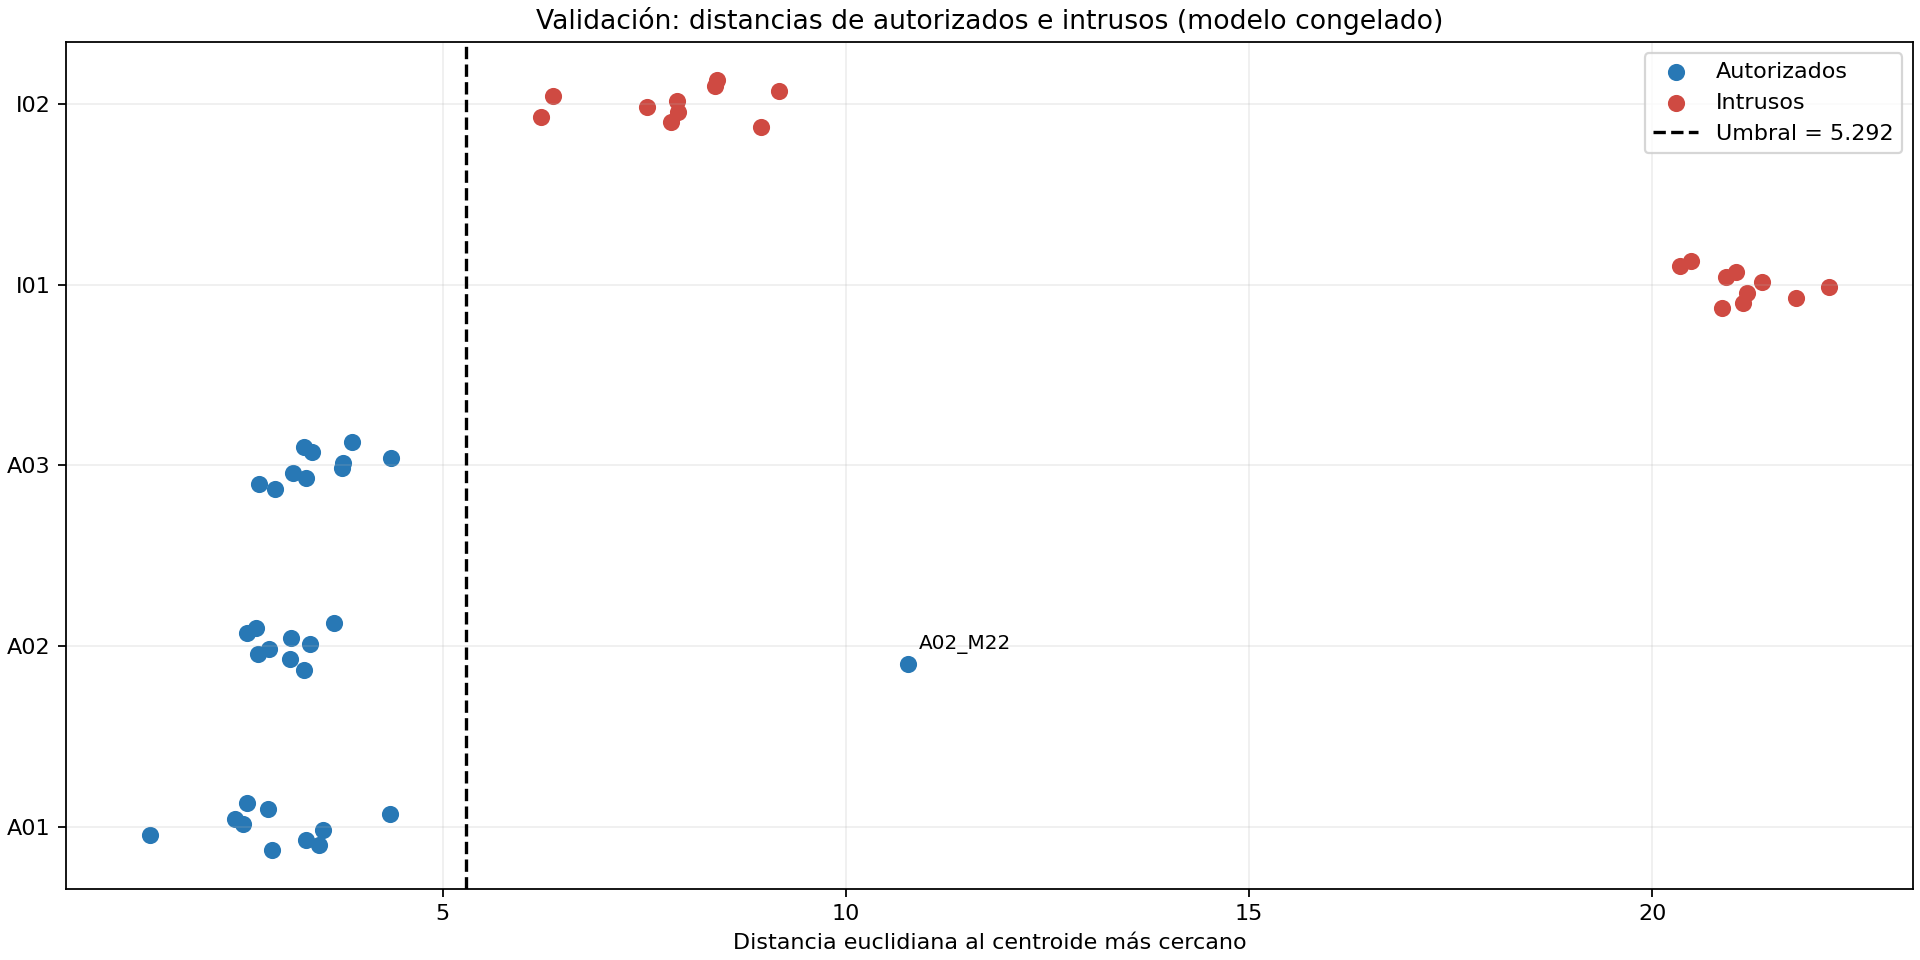

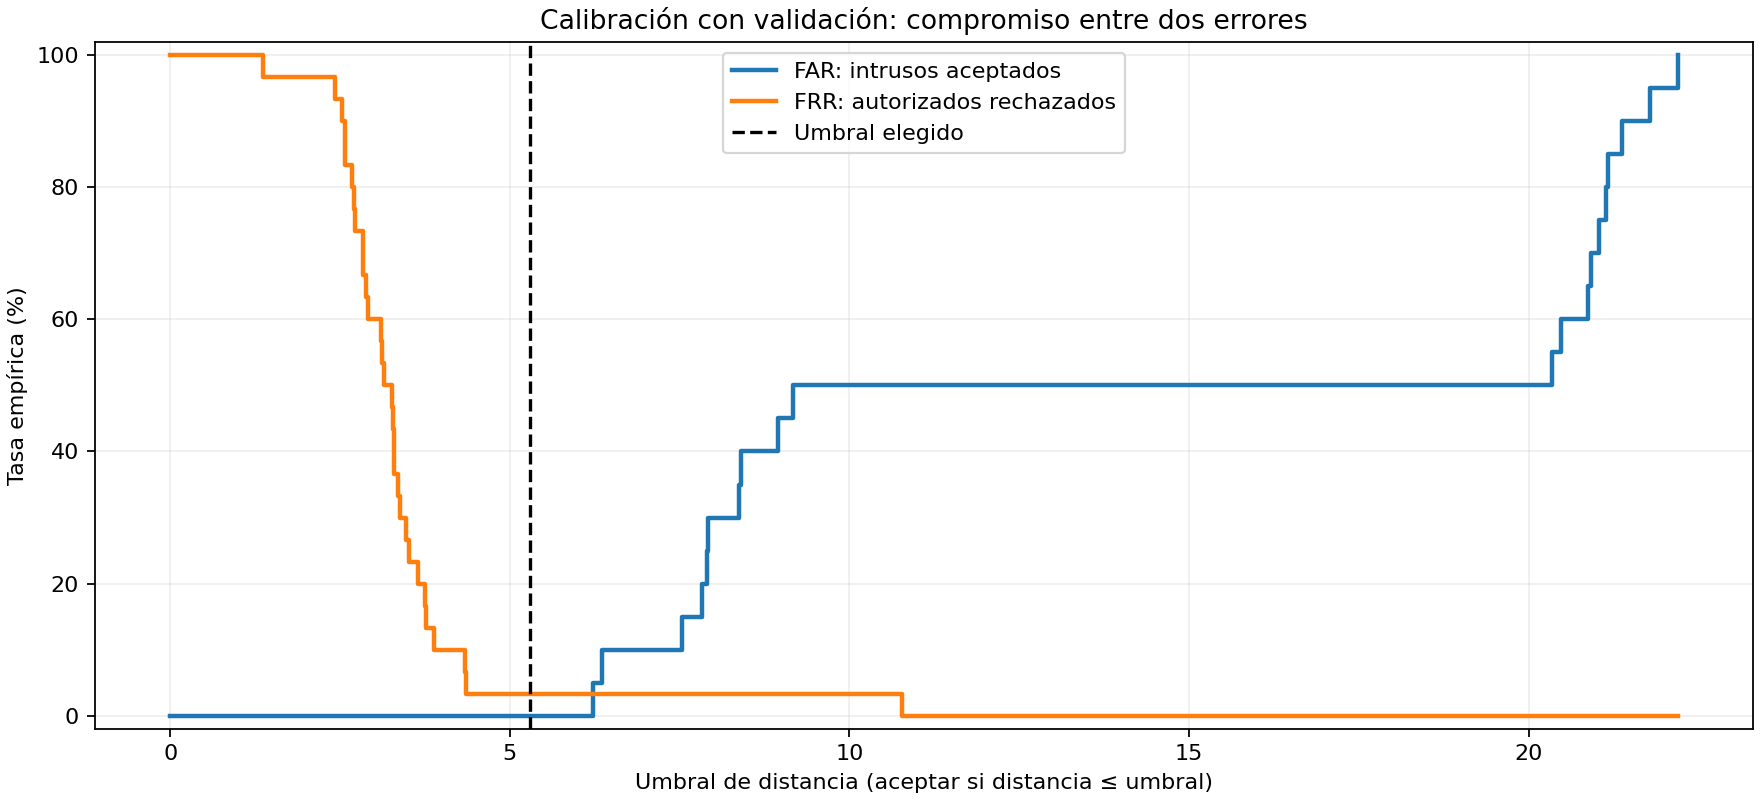

In [6]:
tabla(leer_csv("03_rechazo/matriz_acceso.csv"))
tabla(leer_csv("03_rechazo/resultados_por_identidad.csv"))
resultado = rechazo["resultado_calibracion"]
print("FAR:", round(100*resultado["FAR"], 2), "%")
print("FRR:", round(100*resultado["FRR"], 2), "%")
print("BER:", round(100*resultado["error_balanceado"], 2), "%")
print("Errores conservados:")
tabla(leer_csv("03_rechazo/errores_validacion.csv"),
      ["muestra", "identidad_real", "distancia", "estado", "error"])
figura("03_rechazo/distancias_validacion.png")
figura("03_rechazo/tasas_por_umbral.png")


## Interpretación del error y cierre

El modelo aceptó 29/30 autorizados y rechazó 20/20 intrusos. La identidad de los 29 aceptados
fue correcta. A02_M22 es autorizada: su centroide más cercano sigue siendo A02, pero su
distancia 10.7699 supera tau=5.2922 y queda rechazada. No se eliminó esa muestra.

Los otros 29 autorizados llegan a 4.3614 y la menor distancia intrusa es 6.2230. La frontera
elegida es su punto medio. Subirla hasta aceptar A02_M22 admitiría también diez intrusos.
Con esta distancia y un único límite global no existe separación perfecta de todo el corte.
El 30/30 anterior era identificación forzada entre autorizados; el 29/30 actual agrega rechazo.

El 0/20 de intrusos aceptados proviene de dos bases sintéticas con variantes. No garantiza
FAR igual a cero para cualquier identidad futura. Las métricas se calcularon con la misma
validación usada para calibrar; la prueba final permanece sin evaluar.

Se da por implementada y documentada esta versión de desarrollo: no se sigue purgando
para forzar cero errores. Se guardan juntos selección, escalado, centroides, correspondencia
y umbral para futuras muestras. K-NN de audio, integración y evaluación final siguen pendientes.


## Una sola huella futura y reproducción

Una nueva huella reutiliza el umbral guardado: no define su propio umbral ni mueve centros.
El flujo es imagen → vector 144 → selección 72 → escalado guardado → distancias → decisión.
La decisión no requiere saber su identidad real. El ejemplo de inferencia está en
`documentos/etapas/cierre_etapa06.md`; la función es `decidir_acceso`.

Para reproducir los experimentos completos, consultar los documentos de referencia,
selección y rechazo. Este notebook solo lee las evidencias para evitar recalibraciones
accidentales durante una revisión. Los parámetros NPZ/JSON publicados corresponden al
corte real de Windows y no requieren cargar pickle.

La asistencia de IA, ejemplos de solicitudes y comprobaciones se declaran en
`documentos/uso_ia_generativa.md`. Las pruebas de código verifican contratos e integridad;
no sustituyen la evaluación final independiente.
